# Travelling Salesman Problem – a tour of 10 Universities of Technology in Poland

**Course:** Laboratory of Artificial Intelligence Applications (LZSI)

**Goal:** Use an evolutionary algorithm to find the shortest closed route that visits each of the 10 selected universities of technology exactly once and returns to the starting point.

**Notebook outline:**
1. Input data – coordinates of the universities obtained from a conversational AI
2. Distance matrix (haversine formula, km)
3. Evolutionary algorithm (based on the example from class)
4. Result and convergence plot
5. Verification – exhaustive search of all routes
6. Visualisation of the best route on a map

In [1]:
import numpy as np
import sys
import random
import itertools
import matplotlib.pyplot as plt
from dotenv import load_dotenv
load_dotenv()

# Random seed – makes the results reproducible
random.seed(42)
np.random.seed(42)

## 1. Input data

The geographic coordinates (latitude, longitude) of the main buildings of the universities were obtained from a conversational AI (Gemini, Google).

Prompt: *"Return, in CSV format, the geographic coordinates of the main buildings of 10 universities of technology in Poland: Warsaw, Cracow, Gdańsk, Wrocław, Silesian, Łódź, Poznań, Lublin, Białystok and Rzeszów University of Technology.
Columns: name,city,latitude,longitude (decimal degrees).
Return only the CSV data, with no comments and no ``` markers."*

The coordinates are approximate (accurate to a few hundred metres), which does not matter for distances of hundreds of kilometres.

If the AI request fails (e.g. no API key or no connection) or the response does not pass validation (different columns, a different list of cities, coordinates outside Poland), the data is loaded from the fallback file `politechniki_alt.csv`. Whatever the source, the universities are kept in a fixed order, so index 0 is always the Warsaw University of Technology.

In [2]:
import io
import pandas as pd

CSV_PATH = "politechniki_alt.csv"   # fallback source of coordinates
COLUMNS = ["name", "city", "latitude", "longitude"]
# the fallback CSV uses Polish column names, so they are renamed after loading
CSV_COLUMNS = {"nazwa": "name", "miasto": "city", "szerokosc": "latitude", "dlugosc": "longitude"}
EXPECTED_CITIES = ["Warszawa", "Kraków", "Gdańsk", "Wrocław", "Gliwice",
                   "Łódź", "Poznań", "Lublin", "Białystok", "Rzeszów"]

prompt = """Return, in CSV format, the geographic coordinates (decimal degrees, to 6 decimal places) of the main buildings of 10 universities of technology in Poland:
            Warsaw, Cracow, Gdańsk, Wrocław, Silesian, Łódź, Poznań,
            Lublin, Białystok and Rzeszów University of Technology, starting with the one in Warsaw.
            Columns: name,city,latitude,longitude.
            In the name column use the official Polish name (e.g. Politechnika Warszawska).
            In the city column use these exact Polish city names: Warszawa, Kraków, Gdańsk, Wrocław, Gliwice, Łódź, Poznań, Lublin, Białystok, Rzeszów.
            Return only the CSV data, with no comments and no ``` markers."""


def from_gemini():
    from google import genai
    from google.genai import types
    client = genai.Client()  # API key from the GOOGLE_API_KEY environment variable (or the .env file)
    response = client.models.generate_content(
        model="gemini-3.8-flash",
        contents=prompt,
        config=types.GenerateContentConfig(temperature=0),
    )
    text = response.text.replace("```csv", "").replace("```", "").strip()  # strip ``` markers just in case
    df = pd.read_csv(io.StringIO(text))
    df.columns = df.columns.str.strip()
    return df


def validate(df):
    # returns a list of problems; an empty list means the data is valid
    problems = []
    if list(df.columns) != COLUMNS:
        return [f"invalid columns: {list(df.columns)}"]
    if sorted(df["city"].str.strip()) != sorted(EXPECTED_CITIES):
        problems.append(f"invalid list of cities: {df['city'].tolist()}")
    if not (df["latitude"].between(49.0, 55.0).all() and df["longitude"].between(14.0, 24.2).all()):
        problems.append("coordinates outside Poland")
    return problems


# Primary source: AI; if the request fails or the response is invalid -> CSV file
try:
    df = from_gemini()
    problems = validate(df)
except Exception as e:
    problems = [f"AI request error: {e}"]

if problems:
    print("Problems with the AI data:", problems, file=sys.stderr)
    df = pd.read_csv(CSV_PATH, encoding="utf-8-sig").rename(columns=CSV_COLUMNS)

names  = df["name"].tolist()
cities = df["city"].tolist()
points = list(zip(df["latitude"], df["longitude"]))
no_of_points = len(points)

Problems with the AI data: ["AI request error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}"]


## 2. Distance matrix

We use the **haversine formula** because the data is in geographic coordinates (degrees). It gives the distance along the surface of the Earth (in a straight line, "as the crow flies"), in kilometres.

$$d = 2R \cdot \arcsin\sqrt{\sin^2\frac{\Delta\varphi}{2} + \cos\varphi_1\cos\varphi_2\sin^2\frac{\Delta\lambda}{2}}$$

where $R = 6371$ km is the radius of the Earth, $\varphi$ is latitude and $\lambda$ is longitude (in radians).

In [3]:
def haversine(p1, p2):
    R = 6371.0  # radius of the Earth in km
    lat1, lon1 = np.radians(p1)
    lat2, lon2 = np.radians(p2)
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

distances = np.zeros((no_of_points, no_of_points))

for i in range(no_of_points):
    for j in range(no_of_points):
        if i != j:
            distances[i][j] = haversine(points[i], points[j])

np.set_printoptions(precision=0, suppress=True, linewidth=150)
print("Distance matrix [km]:")
print(distances)

Distance matrix [km]:
[[  0. 250. 287. 299. 269. 119. 277. 152. 175. 255.]
 [250.   0. 487. 234.  93. 189. 333. 225. 404. 148.]
 [287. 487.   0. 378. 454. 297. 245. 437. 329. 536.]
 [299. 234. 378.   0. 146. 181. 144. 383. 472. 370.]
 [269.  93. 454. 146.   0. 171. 264. 292. 440. 240.]
 [119. 189. 297. 181. 171.   0. 186. 222. 293. 263.]
 [277. 333. 245. 144. 264. 186.   0. 406. 424. 441.]
 [152. 225. 437. 383. 292. 222. 406.   0. 213. 140.]
 [175. 404. 329. 472. 440. 293. 424. 213.   0. 353.]
 [255. 148. 536. 370. 240. 263. 441. 140. 353.   0.]]


## 3. Evolutionary algorithm

Building blocks:

- **Individual (chromosome)** – a permutation of university indices, e.g. `[3, 0, 7, ...]` means the route 3 → 0 → 7 → ... → back to 3.
- **Fitness function (`fitness`)** – route length in km (minimised).
- **Selection (`select`)** – roulette wheel: the probability of being selected is inversely proportional to the route length, so shorter routes are more likely to survive.
- **Mutation (`mutate`)** – reversal of a random segment of the route (inversion).
- **Crossover (`cross`)** – a segment of the route is taken from one parent, and the remaining cities are filled in the order they appear in the other parent (no city is repeated).

In [4]:
def create_initial_population(size, no_of_points):
    population = []
    for i in range(size):
        chromosome = np.random.permutation(no_of_points)
        population.append(chromosome)
    return population


def fitness(x, distances):
    # length of the closed route (including the return to the starting point)
    distance = 0
    for i in range(len(x) - 1):
        distance = distance + distances[x[i]][x[i + 1]]
    distance = distance + distances[x[-1]][x[0]]
    return distance


def mutate(x, mutation_prob):
    # inversion of a random segment of the route
    xp = x.copy()
    size = len(xp)
    if random.uniform(0, 1) <= mutation_prob:
        start, end = sorted([random.randrange(size) for _ in range(2)])
        xp[start:end + 1] = xp[start:end + 1][::-1]
    return xp


def cross(xs, crossover_prob):
    par1 = xs[0]
    par2 = xs[1]
    size = len(par1)
    if random.uniform(0, 1) <= crossover_prob:
        ch1, ch2 = [-1] * size, [-1] * size
        start, end = sorted([random.randrange(size) for _ in range(2)])
        # segment copied unchanged from the parent
        for i in range(start, end + 1):
            ch1[i] = par1[i]
            ch2[i] = par2[i]
        # remaining positions filled in the order of the other parent
        for i in range(size):
            if ch1[i] == -1:
                for j in range(size):
                    if par2[j] not in ch1:
                        ch1[i] = par2[j]
                        break
        for i in range(size):
            if ch2[i] == -1:
                for j in range(size):
                    if par1[j] not in ch2:
                        ch2[i] = par1[j]
                        break
        return (np.array(ch1), np.array(ch2))
    else:
        return xs


def evaluate(population, distances):
    evaluations = [fitness(x, distances) for x in population]
    evaluations = [i if i != 0 else 0.01 for i in evaluations]
    return evaluations


def select(population, evaluations):
    # roulette-wheel selection: shorter route -> higher probability
    probabilities = np.array(evaluations) / sum(evaluations)
    probabilities = 1.0 / probabilities
    probabilities = probabilities / probabilities.sum()
    selection = np.random.choice(a=range(population.shape[0]),
                                 size=int(population.shape[0] / 2),
                                 replace=False, p=probabilities)
    return population[selection]


def create_next_generation(selected, population_size, mutation_prob, crossover_prob):
    next_generation = list()
    # mutants
    for i in range(selected.shape[0]):
        next_generation.append(mutate(selected[i], mutation_prob))
    # offspring from crossover
    for i in range(selected.shape[0]):
        selection = np.random.choice(a=range(selected.shape[0]), size=2, replace=False)
        crossed = cross(tuple(selected[selection]), crossover_prob)
        next_generation.append(crossed[0])
        next_generation.append(crossed[1])
    selection2 = np.random.choice(a=range(len(next_generation)), size=population_size, replace=False)
    return np.array([next_generation[index] for index in selection2])

### Algorithm parameters

In the class example the population had only 10 individuals and 5 points. For 10 universities we increase the population to 100 individuals.

In [5]:
population_size = 100     # number of individuals in the population
no_of_generations = 2000  # number of generations
mutation_prob = 0.5       # mutation probability
crossover_prob = 0.3      # crossover probability

### Running the algorithm

In [6]:
population = create_initial_population(population_size, no_of_points)

min_evaluation = sys.float_info.max
min_evaluation_history = list()
best_generation = 0

for i in range(no_of_generations):
    evaluations = evaluate(population, distances)

    if min(evaluations) < min_evaluation:
        min_evaluation = min(evaluations)
        best_solution = population[np.argmin(evaluations)].copy()
        best_generation = i

    selected = select(np.array(population), evaluations)
    population = create_next_generation(selected, population_size, mutation_prob, crossover_prob)

    min_evaluation_history.append(min_evaluation)

print(f"Best route found in generation: {best_generation}")
print(f"Length of the best route: {min_evaluation:.1f} km")

Best route found in generation: 42
Length of the best route: 1721.3 km


## 4. Result

In [7]:
# Rotate the route so that it starts at the Warsaw University of Technology (index 0)
start = list(best_solution).index(0)
best_route = list(best_solution[start:]) + list(best_solution[:start])

print("Best tour:\n")
total = 0
for k in range(len(best_route)):
    a = best_route[k]
    b = best_route[(k + 1) % len(best_route)]
    d = distances[a][b]
    total += d
    print(f"{k+1:2d}. {cities[a]:10s} -> {cities[b]:10s} {d:6.1f} km   (total {total:7.1f} km)")

print(f"\nTotal route length: {total:.1f} km")

Best tour:

 1. Warszawa   -> Białystok   175.2 km   (total   175.2 km)
 2. Białystok  -> Lublin      213.1 km   (total   388.3 km)
 3. Lublin     -> Rzeszów     140.5 km   (total   528.8 km)
 4. Rzeszów    -> Kraków      147.9 km   (total   676.7 km)
 5. Kraków     -> Gliwice      93.3 km   (total   770.0 km)
 6. Gliwice    -> Wrocław     145.8 km   (total   915.8 km)
 7. Wrocław    -> Poznań      144.4 km   (total  1060.2 km)
 8. Poznań     -> Gdańsk      245.1 km   (total  1305.4 km)
 9. Gdańsk     -> Łódź        297.1 km   (total  1602.5 km)
10. Łódź       -> Warszawa    118.8 km   (total  1721.3 km)

Total route length: 1721.3 km


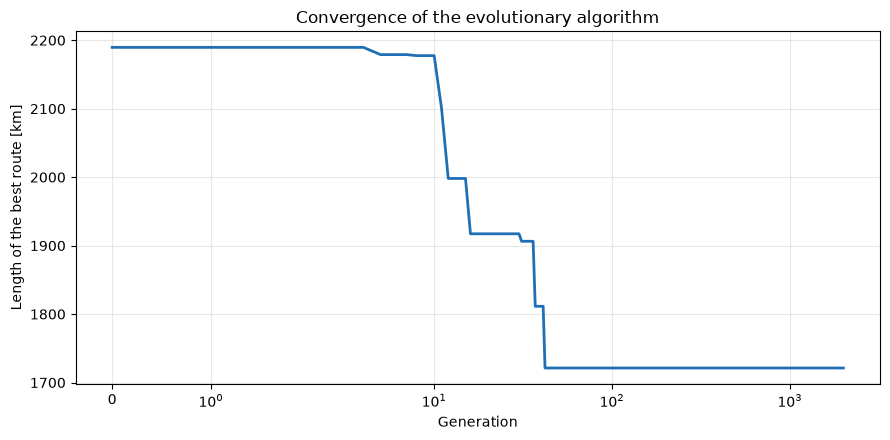

In [8]:
plt.figure(figsize=(9, 4.5))
plt.plot(min_evaluation_history, color="#1f6fb4", linewidth=2)
plt.title("Convergence of the evolutionary algorithm")
plt.xlabel("Generation")
plt.ylabel("Length of the best route [km]")
plt.grid(alpha=0.3)
plt.xscale("symlog")  # logarithmic scale – the first generations are easier to see
plt.tight_layout()
plt.savefig("convergence.png")
plt.show()

## 5. Verification – exhaustive search

For 10 cities the number of distinct closed routes is $\frac{(10-1)!}{2} = 181\,440$, so all of them can be checked and the algorithm's result compared with the true optimum. For more cities (e.g. 20 → about $6 \cdot 10^{16}$ routes) this would be impossible – and that is exactly when evolutionary algorithms become useful.

In [9]:
best_bf = sys.float_info.max
best_bf_route = None

# Fix the starting city (0) and permute the remaining 9
for perm in itertools.permutations(range(1, no_of_points)):
    route = (0,) + perm
    d = fitness(route, distances)
    if d < best_bf:
        best_bf = d
        best_bf_route = route

print(f"Optimum (exhaustive search): {best_bf:.1f} km")
print(f"Evolutionary algorithm:      {min_evaluation:.1f} km")
print("Optimal route:", " -> ".join(cities[i] for i in best_bf_route))

if abs(best_bf - min_evaluation) < 1e-6:
    print("\nThe evolutionary algorithm found the optimal route ✔")
else:
    print(f"\nDifference: {(min_evaluation / best_bf - 1) * 100:.2f}% above the optimum")

Optimum (exhaustive search): 1721.3 km
Evolutionary algorithm:      1721.3 km
Optimal route: Warszawa -> Białystok -> Lublin -> Rzeszów -> Kraków -> Gliwice -> Wrocław -> Poznań -> Gdańsk -> Łódź

The evolutionary algorithm found the optimal route ✔


## 6. Visualisation of the best route

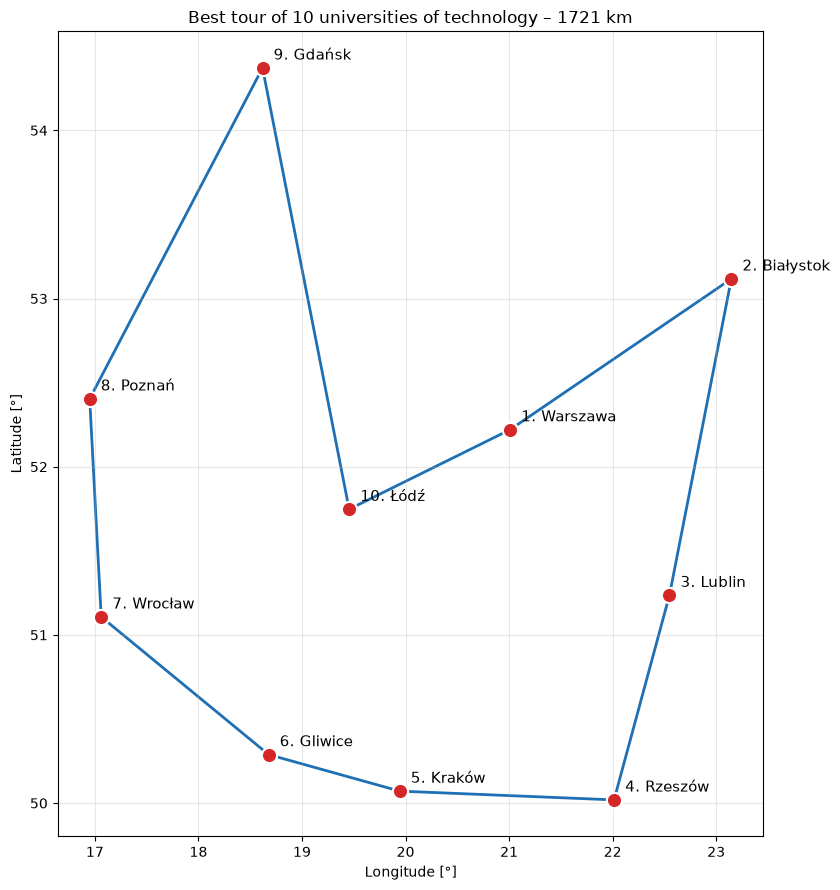

In [10]:
lats = [points[i][0] for i in best_route] + [points[best_route[0]][0]]
lons = [points[i][1] for i in best_route] + [points[best_route[0]][1]]

fig, ax = plt.subplots(figsize=(9, 9))
ax.plot(lons, lats, "-", color="#1f6fb4", linewidth=2, zorder=1)
ax.scatter([p[1] for p in points], [p[0] for p in points], s=120,
           color="#d62728", edgecolor="white", linewidth=1.5, zorder=2)

for k, i in enumerate(best_route):
    ax.annotate(f"{k+1}. {cities[i]}", (points[i][1], points[i][0]),
                textcoords="offset points", xytext=(8, 6), fontsize=11)

ax.set_title(f"Best tour of 10 universities of technology – {min_evaluation:.0f} km")
ax.set_xlabel("Longitude [°]")
ax.set_ylabel("Latitude [°]")
ax.set_aspect(1 / np.cos(np.radians(52)))  # aspect ratio correction for Poland's latitude
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("route.png")
plt.show()

### Interactive map (folium)

In [11]:
import folium

m = folium.Map(location=[52.0, 19.4], zoom_start=6, tiles="OpenStreetMap")

route_coords = [points[i] for i in best_route] + [points[best_route[0]]]
folium.PolyLine(route_coords, color="#1f6fb4", weight=4, opacity=0.8).add_to(m)

for k, i in enumerate(best_route):
    folium.Marker(
        location=points[i],
        popup=f"{k+1}. {names[i]}",
        tooltip=f"{k+1}. {cities[i]}",
        icon=folium.DivIcon(html=f'''
            <div style="background:#d62728;color:white;border-radius:50%;
                        width:26px;height:26px;line-height:26px;text-align:center;
                        font-weight:bold;font-size:13px;border:2px solid white;">{k+1}</div>''')
    ).add_to(m)

m

## Conclusions

- The evolutionary algorithm found a tour of the 10 universities of technology and, as the exhaustive search showed, it is optimal (for straight-line distances).
- The convergence plot shows that the algorithm improves the solution quickly in the first generations, after which the route length stabilises.
- Distances were calculated in a straight line (haversine). The actual road route would be longer (typically by 20–30%), and the order of cities might differ slightly.
- For 10 cities an exhaustive search is still feasible, but for several dozen cities the number of routes grows factorially – that is when an evolutionary algorithm is a practical way to find a good solution in reasonable time.